# 04 — Gradient-boosting baseline with a public feature set

A strong, feature-engineered baseline to compare Chronos-2 against. Rather than designing features
ourselves, we reproduce those of a public top-4% M5 solution:
[btrotta/kaggle-m5](https://github.com/btrotta/kaggle-m5) (`predict.py`).

**What the solution does**
- **Direct strategy:** one model per forecast day. The model for day *k* after the origin only sees sales
  up to the origin, so its sales features are shifted *k* days further into the past. No forecast is fed back
  as an input.
- **Features at three levels of aggregation** (the series, its department in its store, its item over all
  stores): lags of 1 to 7 days, means of the last 7/14/28 days, running mean and variance overall and per
  day of week.
- **Calendar and price:** day of week, month, SNAP day, an "event uplift", the price and its recent change,
  days since the first sale.
- **Training data:** the last year before the origin, December excluded; days before the first sale and
  store closures are excluded from training.

**Deliberate differences with the original**
1. **XGBoost instead of LightGBM**, with the closest equivalent settings (leaf-wise trees with 64 leaves,
   learning rate 0.05, 80% row sampling, L2 penalty 1, at least 20 rows per leaf).
2. **Trained on our 500-series sample** (the original trains on all 30,490 series). The department and item
   features are still computed on **all** series, as in the original. A smaller training set handicaps the model:
   keep this in mind when reading the scores.
3. **Number of boosting rounds:** the original stops early on the forecast window it then reports. We stop early
   on the last 28 days *before* the origin, so no forecast-window value is ever used.
4. **Event uplift:** computed as "mean sales *n* days after the event minus the same weekday one week later",
   which is the intent of the original code (whose implementation also adds small non-zero terms on ordinary days).
5. **Missing days** are defined by the price file (as in notebook 02) rather than by the first sale.

Memory and time: loading all series takes about 1 GB of memory; training is 1 + 28 models per window.

In [1]:
%load_ext autoreload
%autoreload 2

import time

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import xgboost as xgb

from m5_chronos2.data import ARTIFACTS_DIR, HORIZON, ID_COLUMNS, get_roster, list_all_series, roster_name
from m5_chronos2.evaluation import actuals, make_windows
from m5_chronos2.gbdt_features import (
    GROUP_LEVELS,
    LAG_DAYS,
    ROLLING_WINDOWS,
    TRAIN_DAYS,
    calendar_by_day,
    days_since_first_sale,
    event_uplift,
    expanding_stats,
    group_daily_means,
    lag_features,
    load_all_series_long,
    series_features,
)
from m5_chronos2.metrics import HORIZON_BUCKETS, QUANTILE_LEVELS, join_truth, quantile_column, score
from m5_chronos2.plots import MAIN_COLOR, MODEL_COLORS, MUTED_TEXT_COLOR, index_plot, use_blog_style

use_blog_style()

## Settings

In [2]:
SAMPLE_SIZE = 500
SEED = 42
NAME = roster_name(SAMPLE_SIZE, SEED)
MODEL_NAME = "xgboost_btrotta"

# Closest XGBoost equivalent of the original LightGBM settings
XGB_PARAMS = {
    "objective": "reg:squarederror",
    "learning_rate": 0.05,
    "grow_policy": "lossguide",   # grow leaf by leaf, like LightGBM
    "max_leaves": 64,             # LightGBM num_leaves = 64
    "max_depth": 0,               # no depth limit (the number of leaves is the limit)
    "subsample": 0.8,             # LightGBM bagging_fraction = 0.8
    "reg_lambda": 1.0,            # LightGBM lambda_l2 = 1
    "min_child_weight": 20,       # ~ LightGBM's default of 20 rows per leaf
    "tree_method": "hist",
    "enable_categorical": True,
    "random_state": 0,
}
EARLY_STOPPING_ROUNDS = 20
MAX_ROUNDS = 5000

## 1. Load the data

All series (for the department and item features), then our sample with its prices.

In [3]:
calendar = calendar_by_day()
roster = get_roster(list_all_series(), SAMPLE_SIZE, SEED)
roster_ids = roster["id"].to_list()

start = time.time()
all_long = load_all_series_long()
print(f"All series: {all_long.height:,} rows, loaded in {time.time() - start:.0f} s")

sample_long = (
    all_long.filter(pl.col("id").cast(pl.String).is_in(roster_ids))
    .with_columns(pl.col(ID_COLUMNS).cast(pl.String))
)
prices = (
    pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
    .select("id", "date", "sell_price")
    .join(calendar.select("date", "day"), on="date", how="left")
    .drop("date")
)
sample_long = sample_long.join(prices, on=["id", "day"], how="left")
sample_static = series_features(sample_long)

print(f"Our sample: {sample_long['id'].n_unique()} series, {sample_long.height:,} rows")

Reading the frozen roster: roster_n500_seed42.parquet
All series: 24,971,310 rows, loaded in 29 s
Our sample: 500 series, 409,500 rows


## 2. The feature table

`FEATURES` lists every model input, in the order of the original solution.

In [4]:
expanding_columns = [
    f"{level}_{stat}"
    for level in GROUP_LEVELS
    for stat in ("mean", "var", "day_of_week_mean", "day_of_week_var")
]
lag_columns = [
    name
    for level in GROUP_LEVELS
    for name in [f"lag_{n}_{level}" for n in LAG_DAYS] + [f"last_{w}_days_avg_{level}" for w in ROLLING_WINDOWS]
]
FEATURES = (
    ["dept_id", "store_id", "day_of_week", "month", "snap", "days_since_first_sale"]
    + ["sell_price", "sell_price_lag_7", "sell_price_lag_14", "event_uplift"]
    + expanding_columns
    + lag_columns
)
CATEGORICAL_FEATURES = {
    "dept_id": sorted(roster["dept_id"].unique().to_list()),
    "store_id": sorted(roster["store_id"].unique().to_list()),
}
print(f"{len(FEATURES)} features")

52 features


Features that are fixed for a given origin (running statistics, event uplift, days since first sale),
then the lag features, which change with the offset.

In [5]:
def origin_tables(origin_day):
    # Daily series per level, with every value after the origin hidden.
    means = {
        "item_store": group_daily_means(sample_long, GROUP_LEVELS["item_store"], origin_day),
        "dept_store": group_daily_means(all_long, GROUP_LEVELS["dept_store"], origin_day),
        "item": group_daily_means(all_long, GROUP_LEVELS["item"], origin_day),
    }
    uplift = event_uplift(means["item"], origin_day)   # uses every item, as the original
    sample_items = sample_long["item_id"].unique()
    means["item"] = means["item"].filter(pl.col("item_id").is_in(sample_items))

    base = sample_static
    for level, group_columns in GROUP_LEVELS.items():
        stats = expanding_stats(means[level], group_columns, level)
        base = base.join(stats, on=group_columns + ["day"], how="left")
    base = base.join(uplift, on="day", how="left")
    base = base.join(days_since_first_sale(sample_long, origin_day), on=["id", "day"], how="left")
    return base, means


def with_lags(base, means, offset):
    table = base
    for level, group_columns in GROUP_LEVELS.items():
        lags = lag_features(means[level], group_columns, level, offset)
        table = table.join(lags, on=group_columns + ["day"], how="left")
    return table


def training_rows(table, first_day, last_day):
    # Known target, December excluded (as the original)
    return table.filter(
        pl.col("day").is_between(first_day, last_day),
        pl.col("value").is_not_null(),
        pl.col("month") != 12,
    )


def to_xgboost(table):
    # Model inputs as a pandas table, with fixed categories for the categorical columns
    inputs = table.select(FEATURES).to_pandas()
    for column, categories in CATEGORICAL_FEATURES.items():
        inputs[column] = pd.Categorical(inputs[column], categories=categories)
    return inputs

## 3. Train and forecast, for each window

For each window:
1. choose the number of boosting rounds: train the offset-0 model on the year before the origin minus its last
   28 days, and stop when the error on those 28 days stops improving;
2. for each offset k = 0..27, train a model on the full year with that number of rounds, and forecast day
   origin + 1 + k.

In [6]:
windows = make_windows()
day_of_date = dict(zip(calendar["date"].to_list(), calendar["day"].to_list()))
date_of_day = dict(zip(calendar["day"].to_list(), calendar["date"].to_list()))

all_forecasts = []
models_offset_0 = {}

for role, origin_date in zip(windows["role"].to_list(), windows["origin"].to_list()):
    origin_day = day_of_date[origin_date]
    print(f"--- {role} window, origin {origin_date} (day {origin_day})")
    start = time.time()
    base, means = origin_tables(origin_day)

    # 1. Number of rounds, by early stopping on the last 28 days before the origin
    table = with_lags(base, means, offset=0)
    year = training_rows(table, origin_day - TRAIN_DAYS + 1, origin_day)
    fit_part = year.filter(pl.col("day") <= origin_day - HORIZON)
    stop_part = year.filter(pl.col("day") > origin_day - HORIZON)
    probe = xgb.XGBRegressor(n_estimators=MAX_ROUNDS, early_stopping_rounds=EARLY_STOPPING_ROUNDS, **XGB_PARAMS)
    probe.fit(to_xgboost(fit_part), fit_part["value"].to_numpy(),
              eval_set=[(to_xgboost(stop_part), stop_part["value"].to_numpy())], verbose=False)
    n_rounds = probe.best_iteration + 1
    print(f"  boosting rounds: {n_rounds}")

    # 2. One model per forecast day
    for offset in range(HORIZON):
        if offset > 0:
            table = with_lags(base, means, offset)
        year = training_rows(table, origin_day - TRAIN_DAYS + 1, origin_day)
        model = xgb.XGBRegressor(n_estimators=n_rounds, **XGB_PARAMS)
        model.fit(to_xgboost(year), year["value"].to_numpy())
        if offset == 0:
            models_offset_0[role] = model

        target_day = origin_day + 1 + offset
        to_forecast = table.filter(pl.col("day") == target_day)
        forecast = np.clip(model.predict(to_xgboost(to_forecast)), 0, None)   # no negative sales
        all_forecasts.append(pl.DataFrame({
            "id": to_forecast["id"],
            "origin": [origin_date] * to_forecast.height,
            "date": [date_of_day[target_day]] * to_forecast.height,
            "y_pred": forecast.astype(np.float64),
        }))
    print(f"  done in {time.time() - start:.0f} s")

--- validation window, origin 2016-03-27 (day 1885)


/var/folders/k4/pclq47c50r78wfcdxrrbr27c0000gn/T/ipykernel_53006/2906335538.py:10: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  means["item"] = means["item"].filter(pl.col("item_id").is_in(sample_items))


  boosting rounds: 53
  done in 125 s
--- test window, origin 2016-04-24 (day 1913)


/var/folders/k4/pclq47c50r78wfcdxrrbr27c0000gn/T/ipykernel_53006/2906335538.py:10: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  means["item"] = means["item"].filter(pl.col("item_id").is_in(sample_items))


  boosting rounds: 82
  done in 107 s


Save in the standard forecast format. XGBoost gives a point forecast only, so every quantile column is a
copy of `y_pred` (its WQL therefore equals WMAPE / 100).

In [7]:
predictions = pl.concat(all_forecasts).with_columns(
    [pl.col("y_pred").alias(quantile_column(q)) for q in QUANTILE_LEVELS]
).sort("origin", "id", "date")
predictions.write_parquet(ARTIFACTS_DIR / "predictions" / f"{MODEL_NAME}_{NAME}.parquet")
predictions.head()

id,origin,date,y_pred,q0.1,q0.2,q0.3,q0.4,q0.5,q0.6,q0.7,q0.8,q0.9
str,date,date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-28,0.356289,0.356289,0.356289,0.356289,0.356289,0.356289,0.356289,0.356289,0.356289,0.356289
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-29,0.344256,0.344256,0.344256,0.344256,0.344256,0.344256,0.344256,0.344256,0.344256,0.344256
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-30,0.372418,0.372418,0.372418,0.372418,0.372418,0.372418,0.372418,0.372418,0.372418,0.372418
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-03-31,0.367477,0.367477,0.367477,0.367477,0.367477,0.367477,0.367477,0.367477,0.367477,0.367477
"""FOODS_1_001_WI_3_evaluation""",2016-03-27,2016-04-01,0.380113,0.380113,0.380113,0.380113,0.380113,0.380113,0.380113,0.380113,0.380113,0.380113


## 4. Scores, against the naive baselines

Same evaluation roster and metrics as notebook 03. Decisions are made on the validation window only.

In [8]:
sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
truth = actuals(sales)
eval_roster = pl.read_parquet(ARTIFACTS_DIR / f"eval_roster_{NAME}.parquet")

model_names = ["zero", "seasonal_naive", "moving_average_28d", MODEL_NAME]
scored = {
    model: join_truth(pl.read_parquet(ARTIFACTS_DIR / "predictions" / f"{model}_{NAME}.parquet"), truth, eval_roster)
    for model in model_names
}

overall = pl.concat([
    score(table.join(windows.select("origin", "role"), on="origin"), by="role").with_columns(pl.lit(model).alias("model"))
    for model, table in scored.items()
])
overall.select("role", "model", "n_series", "MAE", "WMAPE", "P90", "WQL", "RQL").sort("role", "WMAPE")

role,model,n_series,MAE,WMAPE,P90,WQL,RQL
str,str,u32,f64,f64,f64,f64,f64
"""test""","""xgboost_btrotta""",485,0.948566,76.362099,2.060481,0.763621,36.824994
"""test""","""moving_average_28d""",485,0.963718,77.58187,2.178571,0.775819,37.974645
"""test""","""seasonal_naive""",485,1.176215,94.688482,3.0,0.946885,46.04778
"""test""","""zero""",485,1.242194,100.0,3.0,1.0,20.0
"""validation""","""xgboost_btrotta""",473,0.98117,78.755239,2.13098,0.787552,38.050116
"""validation""","""moving_average_28d""",473,0.991549,79.588312,2.285714,0.795883,39.114156
"""validation""","""seasonal_naive""",473,1.202658,96.533333,3.0,0.965333,46.572121
"""validation""","""zero""",473,1.245847,100.0,3.0,1.0,20.0


/var/folders/k4/pclq47c50r78wfcdxrrbr27c0000gn/T/ipykernel_53006/1172543579.py:20: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


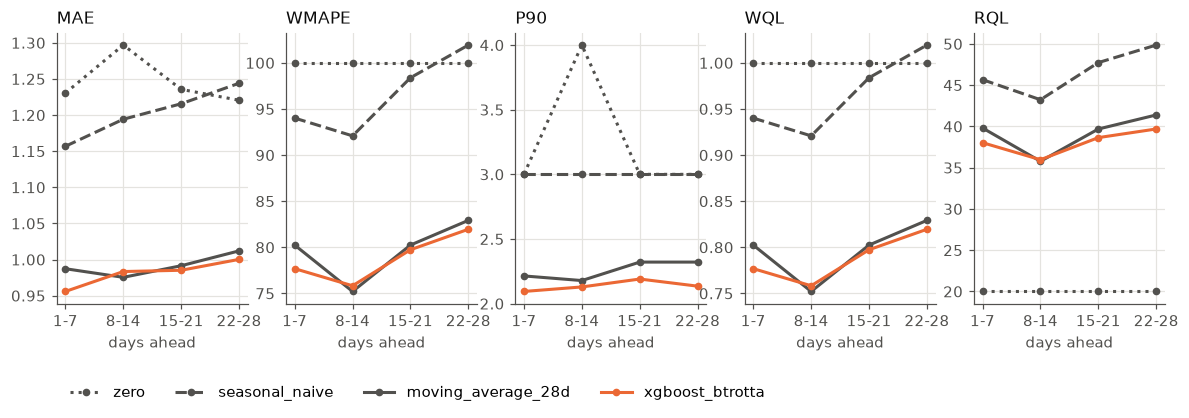

In [9]:
VALIDATION_ORIGIN = windows.filter(pl.col("role") == "validation")["origin"][0]
line_styles = {"zero": ":", "seasonal_naive": "--", "moving_average_28d": "-"}
metrics_to_plot = ["MAE", "WMAPE", "P90", "WQL", "RQL"]
x_positions = range(len(HORIZON_BUCKETS))

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(13, 3.2))
for model, table in scored.items():
    by_bucket = score(table.filter(pl.col("origin") == VALIDATION_ORIGIN), by="horizon_bucket")
    color = MODEL_COLORS.get(model, MUTED_TEXT_COLOR)
    style = line_styles.get(model, "-")
    for ax, metric in zip(axes, metrics_to_plot):
        ax.plot(x_positions, by_bucket[metric].to_numpy(), color=color, linestyle=style,
                marker="o", markersize=4, label=model)
for ax, metric in zip(axes, metrics_to_plot):
    ax.set_title(metric, loc="left")
    ax.set_xticks(list(x_positions))
    ax.set_xticklabels([f"{first}-{last}" for first, last in HORIZON_BUCKETS.values()])
    ax.set_xlabel("days ahead")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.25), ncol=4)
fig.tight_layout()
plt.show()

## 5. Which features does the model rely on?

Gain of each feature in the offset-0 model of the validation window (how much the splits on that feature
reduced the training error, in total). Top 20.

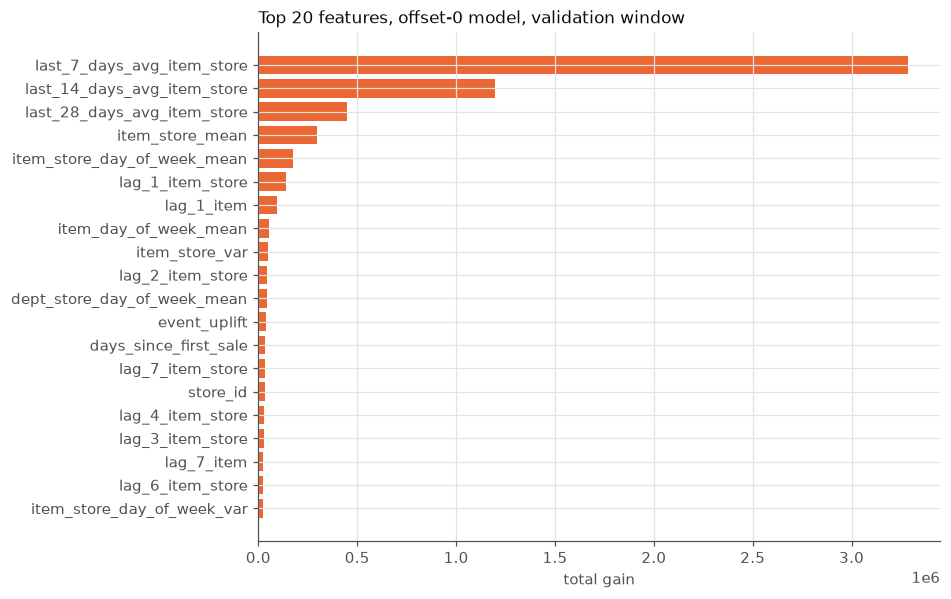

In [10]:
gain = models_offset_0["validation"].get_booster().get_score(importance_type="total_gain")
importance = pl.DataFrame({"feature": list(gain), "gain": list(gain.values())}).sort("gain", descending=True)
top = importance.head(20).reverse()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"].to_list(), top["gain"].to_numpy(), color=MODEL_COLORS[MODEL_NAME])
ax.set_xlabel("total gain")
ax.set_title("Top 20 features, offset-0 model, validation window", loc="left")
plt.show()

## 6. Series by series: XGBoost vs the 28-day moving average

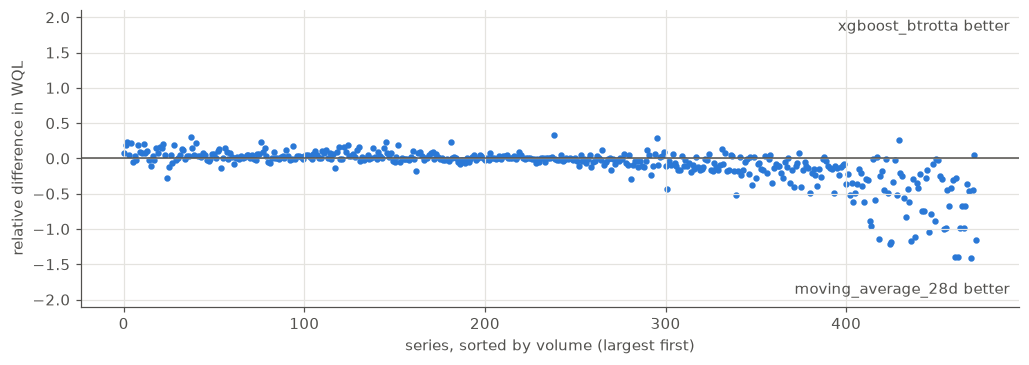

xgboost_btrotta has the lower WQL on 43% of series


In [11]:
def per_series_wql(model):
    table = scored[model].filter(pl.col("origin") == VALIDATION_ORIGIN)
    return score(table, by="id").select("id", pl.col("WQL").alias(f"WQL_{model}"))

volume = (
    scored[MODEL_NAME].filter(pl.col("origin") == VALIDATION_ORIGIN)
    .group_by("id").agg(pl.col("y").sum().alias("volume"))
)
per_series = per_series_wql("moving_average_28d").join(per_series_wql(MODEL_NAME), on="id").join(volume, on="id")

fig, ax = plt.subplots(figsize=(11, 3.5))
share = index_plot(ax, per_series, "WQL", "moving_average_28d", MODEL_NAME, order_by="volume")
plt.show()
print(f"{MODEL_NAME} has the lower WQL on {share:.0%} of series")

## Notes

Looking at both section 6 and section 4, we see that, error wise, xgboost performs well against the naive 28-day moving average model for series with high volume - but conisderably less good when the volume is lower. Also, it isn't surprising that predicitons for the later days are better with xgboost considering that a naive average looses relevance by then (intuitive).